# Green Commuting in California: An Interpretable ML Approach

Examine the socio-economic and structural determinants of “green commuting" (public transit, walking, biking) in California.

## Setup

In [ ]:
import polars as pl
import numpy as np
import shap
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Data: ACS PUMS 2024 1-year person file for California (see README for variables)
try:
    from google.colab import drive
    drive.mount('/drive')
    DATA_PATH = '/drive/My Drive/green_commuting/ACSPUMS2024.csv'   # ← change to your Drive folder
except ImportError:
    DATA_PATH = 'data/ACSPUMS2024.csv'

## Data Cleaning

In [ ]:
df_raw = pl.read_csv(DATA_PATH)
print(f"Raw shape: {df_raw.shape}")

Raw shape: (393725, 20)


In [ ]:
df_raw.head()

PWGTP,WGTP,JWTRNS,SEX,ESR,SCHL,COW,VEH,JWDP,OCCP,POWPUMA,AGEP,WAGP,JWMNP,WKHP,HINCP,NP,NOC,STATE,
i64,i64,i64,i64,i64,i64,i64,i64,i64,str,str,i64,i64,i64,i64,i64,i64,i64,i64,str
78,0,0,1,6,7,2,-1,0,"""9150""","""N""",45,70000,0,56,-60000,1,-1,6,null
39,0,0,1,6,14,0,-1,0,"""N""","""N""",45,0,0,0,-60000,1,-1,6,null
10,0,10,2,1,20,5,-1,88,"""0725""","""03700""",21,3000,5,10,-60000,1,-1,6,null
23,0,0,1,6,18,0,-1,0,"""N""","""N""",28,0,0,0,-60000,1,-1,6,null
53,0,0,2,6,18,1,-1,0,"""1970""","""N""",19,12300,0,10,-60000,1,-1,6,null


In [ ]:
# ckeck POWPUMA -> over 50% missing

print(df_raw["POWPUMA"].value_counts().sort("count", descending=True).head(30))

shape: (30, 2)
┌─────────┬────────┐
│ POWPUMA ┆ count  │
│ ---     ┆ ---    │
│ str     ┆ u32    │
╞═════════╪════════╡
│ N       ┆ 210514 │
│ 03700   ┆ 48439  │
│ 07300   ┆ 16647  │
│ 05900   ┆ 15710  │
│ 08500   ┆ 11827  │
│ …       ┆ …      │
│ 04100   ┆ 1262   │
│ 11300   ┆ 1228   │
│ 00700   ┆ 930    │
│ 04700   ┆ 864    │
│ 00300   ┆ 838    │
└─────────┴────────┘


In [ ]:
# ── Step 1: Replace Census N/A codes (-1, -9, -10) with null ─────────────────
numeric_cols = [col for col, dtype in zip(df_raw.columns, df_raw.dtypes)
                if dtype in (pl.Int64, pl.Int32, pl.Float64, pl.Float32)]

df = df_raw.with_columns([
    pl.when(pl.col(col).is_in([-1, -9, -10]))
      .then(None)
      .otherwise(pl.col(col))
      .alias(col)
    for col in numeric_cols
])

In [ ]:
# ── Step 2: Filter to valid sample ───────────────────────────────────────────
# JWTRNS valid commute codes: 1–10 (excludes 0=N/A, 11=worked from home, 12=other)
VALID_JWTRNS = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

print(f"Before filtering: {len(df):,} rows")

df = df.filter(
    pl.col("AGEP").is_between(18, 64) &
    pl.col("ESR").is_in([1, 2]) &
    pl.col("JWTRNS").is_in(VALID_JWTRNS)
)

print(f"After filtering: {len(df):,} rows")


Before filtering: 393,725 rows
After filtering: 144,966 rows


In [ ]:
# ── Step 3: Build binary target ───────────────────────────────────────────────
GREEN_CODES = [2, 3, 4, 5, 6, 9, 10] # 2: Bus, 3: Subway, 4: Long-distance or cummuter rail, 5: Light rail, streetcar, or trolley, 6: Ferryboat, 9: Bicycle, 10: Walked

df = df.with_columns(
    pl.col("JWTRNS").is_in(GREEN_CODES).cast(pl.Int8).alias("green_commute")
)

print(f"Green commute rate: {df['green_commute'].mean():.1%}")

Green commute rate: 7.6%


In [ ]:
# ── Step 4: Feature engineering ──────────────────────────────────────────────
occ = pl.col("OCCP").cast(pl.Float64, strict=False).cast(pl.Int64, strict=False)
df = df.with_columns([

    # Log-transform income
    pl.col("WAGP").clip(lower_bound=0).log1p().alias("log_wagp"),
    pl.col("HINCP").clip(lower_bound=0).log1p().alias("log_hincp"),

    # Cap vehicles at 4
    pl.col("VEH").clip(upper_bound=4),

    # Vehicles per adult
    (pl.col("VEH") / pl.col("NP").clip(lower_bound=1)).alias("veh_per_adult"),

    # Education bins
    pl.when(pl.col("SCHL") < 16).then(pl.lit("no_hs"))
      .when(pl.col("SCHL") < 20).then(pl.lit("hs_ged"))
      .when(pl.col("SCHL") < 21).then(pl.lit("some_college"))
      .when(pl.col("SCHL") == 21).then(pl.lit("bachelors"))
      .when(pl.col("SCHL") > 21).then(pl.lit("graduate"))
      .otherwise(None)
      .alias("edu_bin"),

    # Sex
    pl.when(pl.col("SEX") == 1).then(pl.lit("male"))
    .when(pl.col("SEX") == 2).then(pl.lit("female"))
    .otherwise(None)
    .alias("sex"),

    # Departure time buckets
    pl.when(pl.col("JWDP") <= 24).then(pl.lit("overnight"))
      .when(pl.col("JWDP") <= 72).then(pl.lit("early_morning"))
      .when(pl.col("JWDP") <= 108).then(pl.lit("am_peak"))
      .when(pl.col("JWDP") <= 156).then(pl.lit("midday"))
      .when(pl.col("JWDP") <= 204).then(pl.lit("pm_peak"))
      .when(pl.col("JWDP") > 204).then(pl.lit("evening"))
      .otherwise(None)
      .alias("dep_bucket"),

    # Occupation groups
      pl.when(occ <= 440).then(pl.lit("management"))
      .when(occ <= 960).then(pl.lit("business_finance"))
      .when(occ <= 1240).then(pl.lit("computer_math"))
      .when(occ <= 1560).then(pl.lit("engineering"))
      .when(occ <= 1980).then(pl.lit("science"))
      .when(occ <= 2060).then(pl.lit("community_social"))
      .when(occ <= 2180).then(pl.lit("legal"))
      .when(occ <= 2555).then(pl.lit("education_library"))
      .when(occ <= 2920).then(pl.lit("arts_media"))
      .when(occ <= 3550).then(pl.lit("healthcare_practitioners"))
      .when(occ <= 3655).then(pl.lit("healthcare_support"))
      .when(occ <= 3960).then(pl.lit("protective_service"))
      .when(occ <= 4160).then(pl.lit("food_service"))
      .when(occ <= 4255).then(pl.lit("building_grounds"))
      .when(occ <= 4655).then(pl.lit("personal_service"))
      .when(occ <= 4965).then(pl.lit("sales"))
      .when(occ <= 5940).then(pl.lit("office_admin"))
      .when(occ <= 6130).then(pl.lit("farming_fishing_forestry"))
      .when(occ <= 6950).then(pl.lit("construction_extraction"))
      .when(occ <= 7640).then(pl.lit("repair_maintenance"))
      .when(occ <= 8990).then(pl.lit("production"))
      .when(occ <= 9430).then(pl.lit("transportation"))
      .when(occ <= 9760).then(pl.lit("material_moving"))
      .when(occ <= 9830).then(pl.lit("military"))
      .otherwise(None)  # 9920 = never worked, shouldn't survive ESR filter anyway
      .alias("occ_group")
      ])


In [ ]:
# ── Step 5: Drop rows missing critical features ───────────────────────────────
CRITICAL_COLS = ["VEH", "HINCP", "SCHL", "AGEP", "OCCP"]
before = len(df)
df = df.drop_nulls(subset=CRITICAL_COLS)
print(f"Dropped {before - len(df):,} rows missing critical features")
print(f"Final shape: {df.shape}")
print(f"Final green commute rate: {df['green_commute'].mean():.1%}")

# ── Step 6: Save ──────────────────────────────────────────────────────────────
df.write_csv("acs_pums_ca_clean.csv")
print("✓ Saved to acs_pums_ca_clean.csv")

Dropped 2,444 rows missing critical features
Final shape: (142522, 28)
Final green commute rate: 6.7%
✓ Saved to acs_pums_ca_clean.csv


## EDA

In [ ]:
df = pl.read_csv(
    "acs_pums_ca_clean.csv",
    null_values=["", "N", "N/A"],
    infer_schema_length=10000
)

# Plot styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 130
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

### 1. Target Variable - Class Imbalance

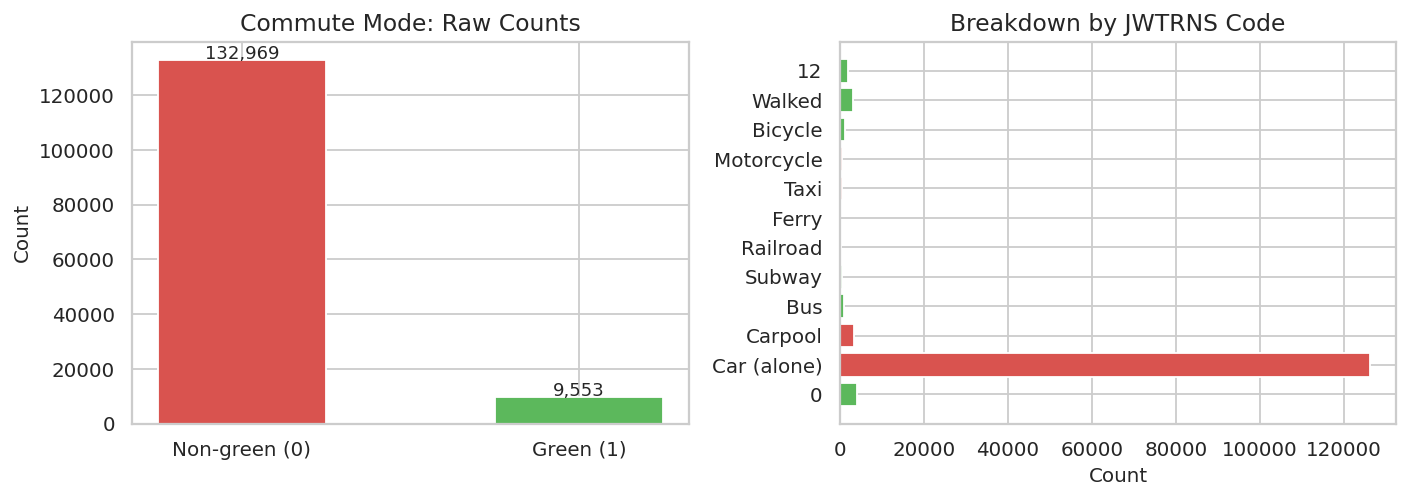

Green commute rate: 6.7%
Class ratio (non-green:green): 13.9:1


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Raw counts
counts = df["green_commute"].value_counts().sort("green_commute")
axes[0].bar(["Non-green (0)", "Green (1)"],
            counts["count"].to_list(),
            color=["#d9534f", "#5cb85c"], edgecolor="white", width=0.5)
axes[0].set_title("Commute Mode: Raw Counts")
axes[0].set_ylabel("Count")
for i, v in enumerate(counts["count"].to_list()):
    axes[0].text(i, v + 500, f"{v:,}", ha="center", fontsize=10)

# JWTRNS breakdown
jwtrns_labels = {
    1: "Car (alone)", 2: "Carpool", 3: "Bus", 4: "Subway",
    5: "Railroad", 6: "Ferry", 7: "Taxi", 8: "Motorcycle",
    9: "Bicycle", 10: "Walked"
}
jwtrns_counts = (
    df.group_by("JWTRNS").agg(pl.len().alias("count"))
      .sort("JWTRNS")
      .with_columns(
          pl.col("JWTRNS").cast(pl.String).replace({
              "1": "Car (alone)", "2": "Carpool", "3": "Bus", "4": "Subway",
              "5": "Railroad", "6": "Ferry", "7": "Taxi", "8": "Motorcycle",
              "9": "Bicycle", "10": "Walked"
          }).alias("label")
      )
)
colors = ["#d9534f" if int(k) in [1,2,7,8] else "#5cb85c"
          for k in jwtrns_counts["JWTRNS"].to_list()]
axes[1].barh(jwtrns_counts["label"].to_list(),
             jwtrns_counts["count"].to_list(),
             color=colors, edgecolor="white")
axes[1].set_title("Breakdown by JWTRNS Code")
axes[1].set_xlabel("Count")

plt.tight_layout()
plt.show()

print(f"Green commute rate: {df['green_commute'].mean():.1%}")
print(f"Class ratio (non-green:green): {(1 - df['green_commute'].mean()) / df['green_commute'].mean():.1f}:1")

### 2. Socioeconomic Features

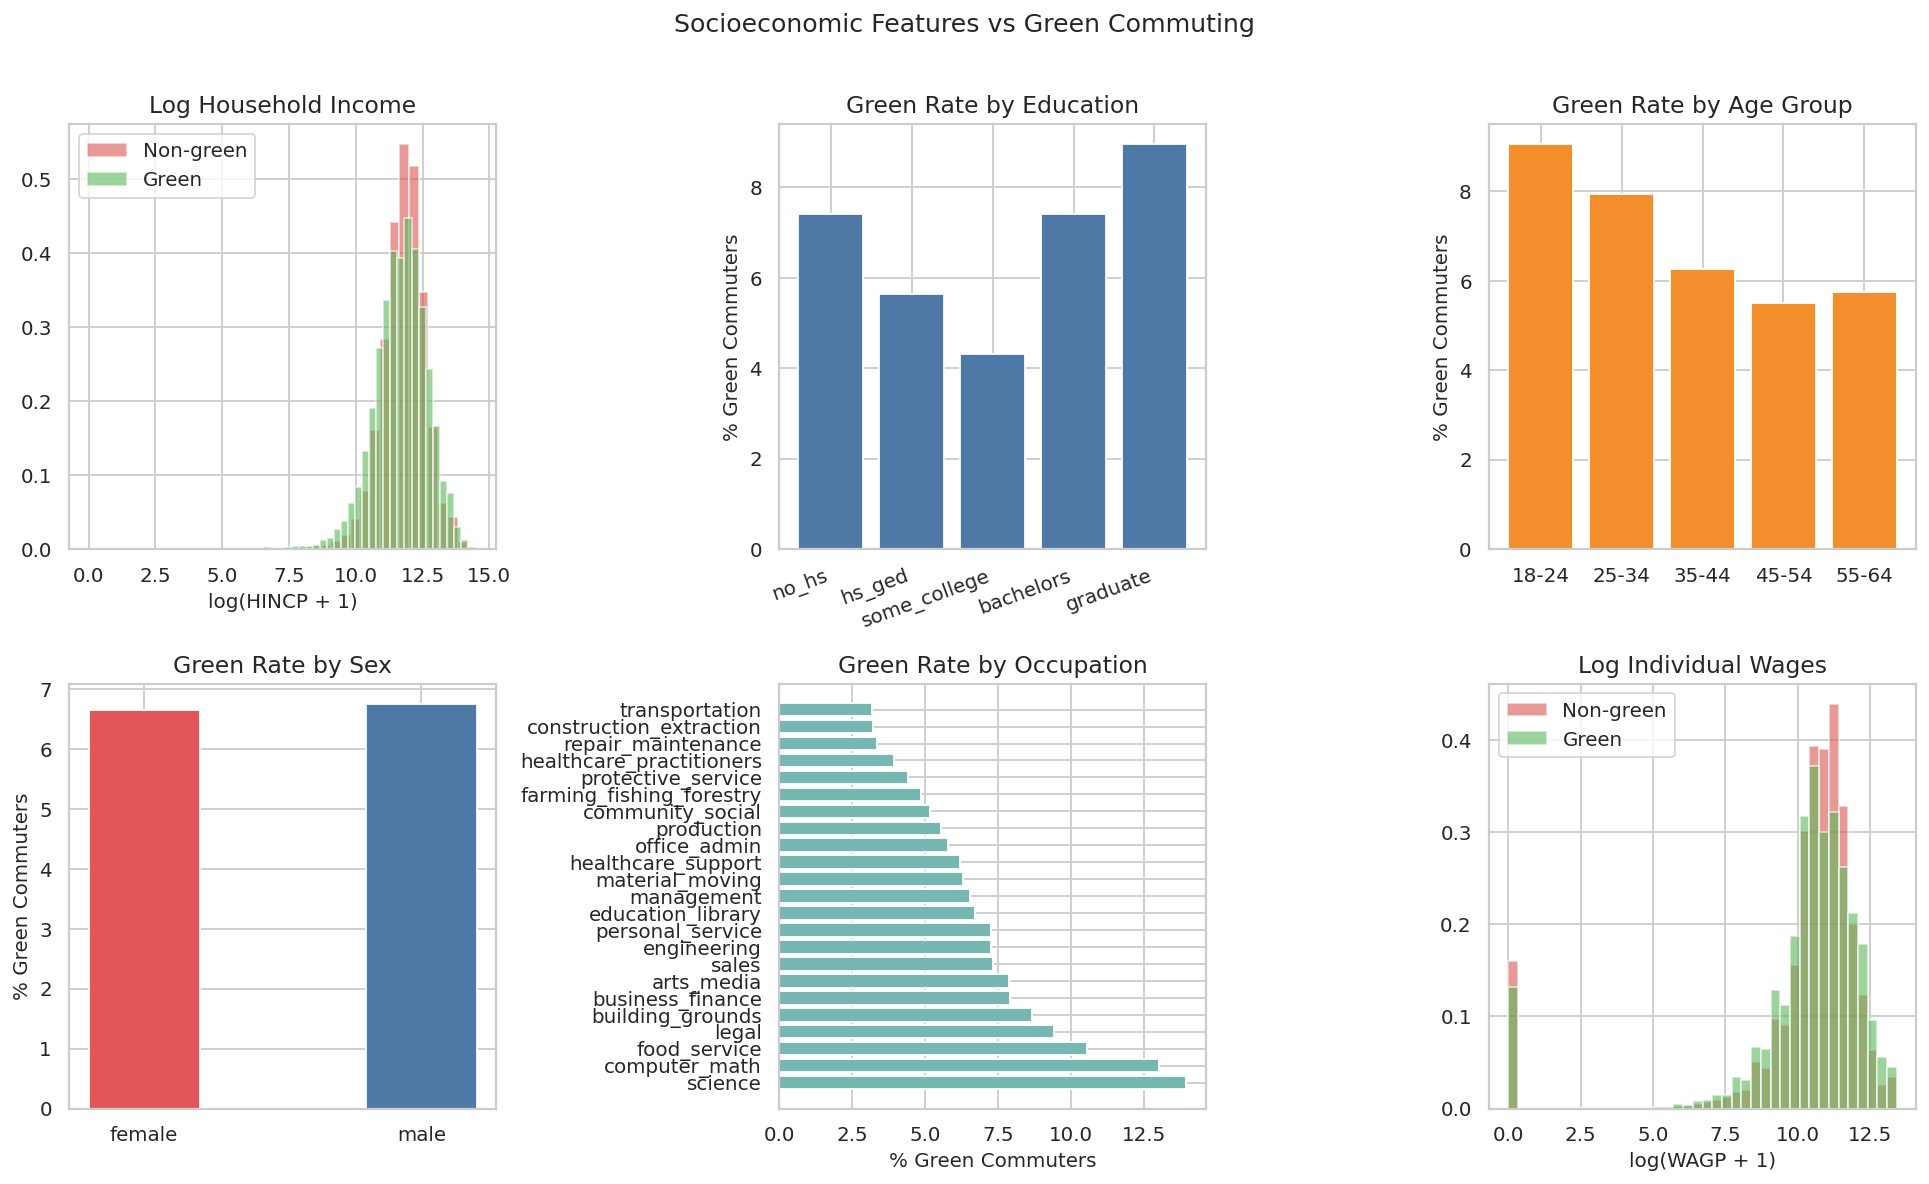

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

# ── Income distribution by commute type ──────────────────────────────────────
green = df.filter(pl.col("green_commute") == 1)["log_hincp"].drop_nulls().to_numpy()
nongreen = df.filter(pl.col("green_commute") == 0)["log_hincp"].drop_nulls().to_numpy()
axes[0,0].hist(nongreen, bins=40, alpha=0.6, color="#d9534f", label="Non-green", density=True)
axes[0,0].hist(green,    bins=40, alpha=0.6, color="#5cb85c", label="Green",     density=True)
axes[0,0].set_title("Log Household Income")
axes[0,0].set_xlabel("log(HINCP + 1)")
axes[0,0].legend()

# ── Green rate by education ───────────────────────────────────────────────────
edu_order = ["no_hs", "hs_ged", "some_college", "bachelors", "graduate"]
edu_rates = (
    df.group_by("edu_bin")
      .agg((pl.col("green_commute").mean() * 100).alias("green_rate"))
      .filter(pl.col("edu_bin").is_in(edu_order))
)
edu_rates = edu_rates.with_columns(
    pl.col("edu_bin").cast(pl.Enum(edu_order))
).sort("edu_bin")
axes[0,1].bar(edu_rates["edu_bin"].to_list(),
              edu_rates["green_rate"].to_list(),
              color="#4e79a7", edgecolor="white")
axes[0,1].set_title("Green Rate by Education")
axes[0,1].set_ylabel("% Green Commuters")
axes[0,1].set_xticks(range(len(edu_rates)))
axes[0,1].set_xticklabels(edu_rates["edu_bin"].to_list(), rotation=20, ha="right")

# ── Green rate by age bin ─────────────────────────────────────────────────────
df = df.with_columns(
    pl.when(pl.col("AGEP") < 25).then(pl.lit("18-24"))
      .when(pl.col("AGEP") < 35).then(pl.lit("25-34"))
      .when(pl.col("AGEP") < 45).then(pl.lit("35-44"))
      .when(pl.col("AGEP") < 55).then(pl.lit("45-54"))
      .otherwise(pl.lit("55-64"))
      .alias("age_bin")
)
age_order = ["18-24", "25-34", "35-44", "45-54", "55-64"]
age_rates = (
    df.group_by("age_bin")
      .agg((pl.col("green_commute").mean() * 100).alias("green_rate"))
      .with_columns(pl.col("age_bin").cast(pl.Enum(age_order)))
      .sort("age_bin")
)
axes[0,2].bar(age_rates["age_bin"].to_list(),
              age_rates["green_rate"].to_list(),
              color="#f28e2b", edgecolor="white")
axes[0,2].set_title("Green Rate by Age Group")
axes[0,2].set_ylabel("% Green Commuters")

# ── Green rate by sex ─────────────────────────────────────────────────────────
sex_rates = (
    df.group_by("sex")
      .agg((pl.col("green_commute").mean() * 100).alias("green_rate"))
      .drop_nulls()
      .sort("sex")
)
axes[1,0].bar(sex_rates["sex"].to_list(),
              sex_rates["green_rate"].to_list(),
              color=["#e15759", "#4e79a7"], edgecolor="white", width=0.4)
axes[1,0].set_title("Green Rate by Sex")
axes[1,0].set_ylabel("% Green Commuters")

# ── Green rate by occupation ──────────────────────────────────────────────────
occ_rates = (
    df.group_by("occ_group")
      .agg((pl.col("green_commute").mean() * 100).alias("green_rate"),
           pl.len().alias("n"))
      .drop_nulls()
      .filter(pl.col("n") > 100)
      .sort("green_rate", descending=True)
)
axes[1,1].barh(occ_rates["occ_group"].to_list(),
               occ_rates["green_rate"].to_list(),
               color="#76b7b2", edgecolor="white")
axes[1,1].set_title("Green Rate by Occupation")
axes[1,1].set_xlabel("% Green Commuters")

# ── Log wage distribution ─────────────────────────────────────────────────────
green_w = df.filter(pl.col("green_commute") == 1)["log_wagp"].drop_nulls().to_numpy()
ngreen_w = df.filter(pl.col("green_commute") == 0)["log_wagp"].drop_nulls().to_numpy()
axes[1,2].hist(ngreen_w, bins=40, alpha=0.6, color="#d9534f", label="Non-green", density=True)
axes[1,2].hist(green_w,  bins=40, alpha=0.6, color="#5cb85c", label="Green",     density=True)
axes[1,2].set_title("Log Individual Wages")
axes[1,2].set_xlabel("log(WAGP + 1)")
axes[1,2].legend()

plt.suptitle("Socioeconomic Features vs Green Commuting", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### 3. Structural Factors

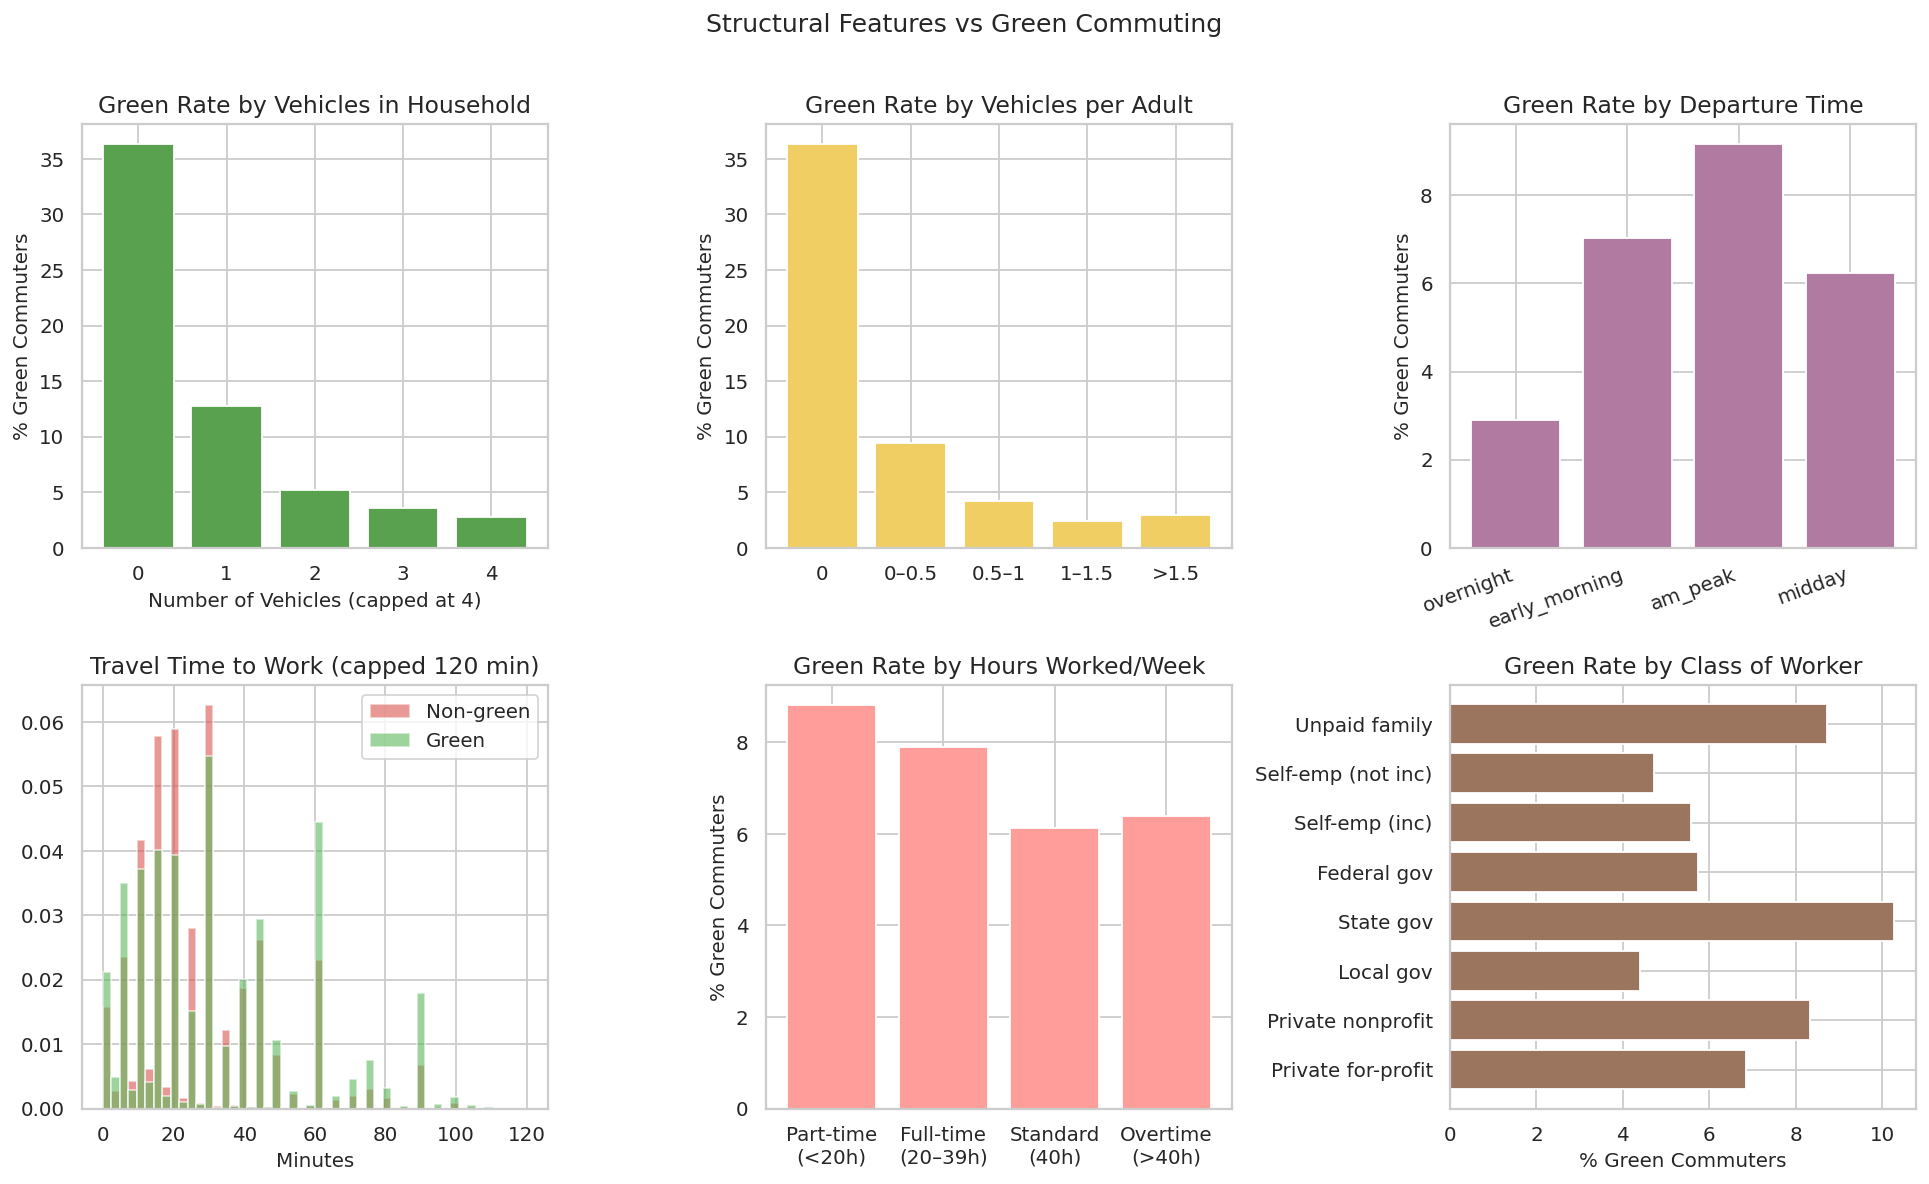

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

# ── Vehicles available ────────────────────────────────────────────────────────
veh_rates = (
    df.group_by("VEH")
      .agg((pl.col("green_commute").mean() * 100).alias("green_rate"),
           pl.len().alias("n"))
      .drop_nulls()
      .sort("VEH")
)
axes[0,0].bar([str(int(v)) for v in veh_rates["VEH"].to_list()],
              veh_rates["green_rate"].to_list(),
              color="#59a14f", edgecolor="white")
axes[0,0].set_title("Green Rate by Vehicles in Household")
axes[0,0].set_xlabel("Number of Vehicles (capped at 4)")
axes[0,0].set_ylabel("% Green Commuters")

# ── Vehicles per adult ────────────────────────────────────────────────────────
df = df.with_columns(
    pl.when(pl.col("veh_per_adult") == 0).then(pl.lit("0"))
      .when(pl.col("veh_per_adult") <= 0.5).then(pl.lit("0–0.5"))
      .when(pl.col("veh_per_adult") <= 1.0).then(pl.lit("0.5–1"))
      .when(pl.col("veh_per_adult") <= 1.5).then(pl.lit("1–1.5"))
      .otherwise(pl.lit(">1.5"))
      .alias("vpa_bin")
)
vpa_order = ["0", "0–0.5", "0.5–1", "1–1.5", ">1.5"]
vpa_rates = (
    df.group_by("vpa_bin")
      .agg((pl.col("green_commute").mean() * 100).alias("green_rate"))
      .with_columns(pl.col("vpa_bin").cast(pl.Enum(vpa_order)))
      .sort("vpa_bin")
)
axes[0,1].bar(vpa_rates["vpa_bin"].to_list(),
              vpa_rates["green_rate"].to_list(),
              color="#f1ce63", edgecolor="white")
axes[0,1].set_title("Green Rate by Vehicles per Adult")
axes[0,1].set_ylabel("% Green Commuters")

# ── Departure time bucket ─────────────────────────────────────────────────────
dep_order = ["overnight", "early_morning", "am_peak", "midday", "pm_peak", "evening"]
dep_rates = (
    df.group_by("dep_bucket")
      .agg((pl.col("green_commute").mean() * 100).alias("green_rate"))
      .drop_nulls()
      .with_columns(pl.col("dep_bucket").cast(pl.Enum(dep_order)))
      .sort("dep_bucket")
)
axes[0,2].bar(dep_rates["dep_bucket"].to_list(),
              dep_rates["green_rate"].to_list(),
              color="#b07aa1", edgecolor="white")
axes[0,2].set_title("Green Rate by Departure Time")
axes[0,2].set_ylabel("% Green Commuters")
axes[0,2].set_xticks(range(len(dep_rates)))
axes[0,2].set_xticklabels(dep_rates["dep_bucket"].to_list(), rotation=20, ha="right")

# ── Travel time distribution ──────────────────────────────────────────────────
green_t  = df.filter(pl.col("green_commute") == 1)["JWMNP"].drop_nulls().to_numpy()
ngreen_t = df.filter(pl.col("green_commute") == 0)["JWMNP"].drop_nulls().to_numpy()
axes[1,0].hist(ngreen_t, bins=50, alpha=0.6, color="#d9534f", label="Non-green",
               density=True, range=(0, 120))
axes[1,0].hist(green_t,  bins=50, alpha=0.6, color="#5cb85c", label="Green",
               density=True, range=(0, 120))
axes[1,0].set_title("Travel Time to Work (capped 120 min)")
axes[1,0].set_xlabel("Minutes")
axes[1,0].legend()

# ── Hours worked per week ─────────────────────────────────────────────────────
df = df.with_columns(
    pl.when(pl.col("WKHP") < 20).then(pl.lit("Part-time\n(<20h)"))
      .when(pl.col("WKHP") < 40).then(pl.lit("Full-time\n(20–39h)"))
      .when(pl.col("WKHP") == 40).then(pl.lit("Standard\n(40h)"))
      .otherwise(pl.lit("Overtime\n(>40h)"))
      .alias("wkhp_bin")
)
wkhp_order = ["Part-time\n(<20h)", "Full-time\n(20–39h)", "Standard\n(40h)", "Overtime\n(>40h)"]
wkhp_rates = (
    df.group_by("wkhp_bin")
      .agg((pl.col("green_commute").mean() * 100).alias("green_rate"))
      .drop_nulls()
      .with_columns(pl.col("wkhp_bin").cast(pl.Enum(wkhp_order)))
      .sort("wkhp_bin")
)
axes[1,1].bar(wkhp_rates["wkhp_bin"].to_list(),
              wkhp_rates["green_rate"].to_list(),
              color="#ff9d9a", edgecolor="white")
axes[1,1].set_title("Green Rate by Hours Worked/Week")
axes[1,1].set_ylabel("% Green Commuters")

# ── Class of worker ───────────────────────────────────────────────────────────
cow_labels = {
    1: "Private for-profit", 2: "Private nonprofit",
    3: "Local gov", 4: "State gov", 5: "Federal gov",
    6: "Self-emp (inc)", 7: "Self-emp (not inc)", 8: "Unpaid family"
}
cow_rates = (
    df.group_by("COW")
      .agg((pl.col("green_commute").mean() * 100).alias("green_rate"),
           pl.len().alias("n"))
      .drop_nulls()
      .filter(pl.col("n") > 200)
      .sort("COW")
      .with_columns(
          pl.col("COW").cast(pl.String).replace({
              "1": "Private for-profit", "2": "Private nonprofit",
              "3": "Local gov", "4": "State gov", "5": "Federal gov",
              "6": "Self-emp (inc)", "7": "Self-emp (not inc)", "8": "Unpaid family"
          }).alias("label")
      )
)
axes[1,2].barh(cow_rates["label"].to_list(),
               cow_rates["green_rate"].to_list(),
               color="#9c755f", edgecolor="white")
axes[1,2].set_title("Green Rate by Class of Worker")
axes[1,2].set_xlabel("% Green Commuters")

plt.suptitle("Structural Features vs Green Commuting", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### 4. Summary Stats

In [ ]:
summary = (
    df.group_by("green_commute")
      .agg([
          pl.col("AGEP").mean().alias("avg_age"),
          pl.col("HINCP").median().alias("median_hincp"),
          pl.col("VEH").mean().alias("avg_vehicles"),
          pl.col("JWMNP").mean().alias("avg_commute_min"),
          pl.col("WKHP").mean().alias("avg_hrs_worked"),
          pl.len().alias("n"),
      ])
      .sort("green_commute")
)
print(summary)

shape: (2, 7)
┌───────────────┬───────────┬──────────────┬──────────────┬───────────────┬───────────────┬────────┐
│ green_commute ┆ avg_age   ┆ median_hincp ┆ avg_vehicles ┆ avg_commute_m ┆ avg_hrs_worke ┆ n      │
│ ---           ┆ ---       ┆ ---          ┆ ---          ┆ in            ┆ d             ┆ ---    │
│ i64           ┆ f64       ┆ f64          ┆ f64          ┆ ---           ┆ ---           ┆ u32    │
│               ┆           ┆              ┆              ┆ f64           ┆ f64           ┆        │
╞═══════════════╪═══════════╪══════════════╪══════════════╪═══════════════╪═══════════════╪════════╡
│ 0             ┆ 41.338868 ┆ 140000.0     ┆ 2.459528     ┆ 28.715656     ┆ 38.392761     ┆ 132969 │
│ 1             ┆ 38.997697 ┆ 128300.0     ┆ 1.584842     ┆ 35.511881     ┆ 37.191354     ┆ 9553   │
└───────────────┴───────────┴──────────────┴──────────────┴───────────────┴───────────────┴────────┘


## Machine Learning

Two models are trained and compared:
- **Random Forest** (baseline) — `class_weight='balanced'`
- **XGBoost** (primary) — `scale_pos_weight = n_neg / n_pos`

Both approaches re-weight the loss function to penalise misclassification of the minority class (green commuters, ~6.7 % of the sample) proportionally to the class imbalance ratio. This avoids the degenerate solution of predicting "non-green" for every observation.

Evaluation metrics: **ROC-AUC**, **AUPRC** (Area Under Precision-Recall Curve), and **F1-score** — all more informative than accuracy under class imbalance. Cross-validation uses **5-fold stratified K-Fold** to preserve the class ratio in every fold.

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    average_precision_score,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)
import xgboost as xgb
import warnings
warnings.filterwarnings("ignore")


### 1. Feature Preparation & Preprocessing Pipeline

Numeric features are median-imputed and standardised. Categorical features are mode-imputed and one-hot encoded (unknown categories silently ignored). The full pipeline prevents data leakage by fitting all transformers on the training fold only.

In [ ]:
# ── Feature selection ─────────────────────────────────────────────────────────
NUM_FEATURES = ["AGEP", "log_wagp", "log_hincp", "VEH", "veh_per_adult",
                "NP", "NOC", "JWMNP", "WKHP"]
CAT_FEATURES = ["edu_bin", "sex", "dep_bucket", "occ_group"]

ml_cols = NUM_FEATURES + CAT_FEATURES + ["green_commute"]
df_ml = df.select([c for c in ml_cols if c in df.columns]).to_pandas()

# Drop rows with any missing value across all features and the target.
# Missingness in ACS PUMS is largely structural (e.g. no wage income = null WAGP),
# not random, so listwise deletion is more appropriate than imputation.
before = len(df_ml)
df_ml = df_ml.dropna(subset=NUM_FEATURES + CAT_FEATURES + ["green_commute"])
print(f"Dropped {before - len(df_ml):,} rows with missing feature values ({(before - len(df_ml))/before:.1%})")

X = df_ml[NUM_FEATURES + CAT_FEATURES]
y = df_ml["green_commute"].astype(int)

print(f"Feature matrix : {X.shape[0]:,} rows × {X.shape[1]} features")
print(f"  Numeric      : {NUM_FEATURES}")
print(f"  Categorical  : {CAT_FEATURES}")
print(f"Target distribution:\n{y.value_counts().rename({0:'Non-green',1:'Green'})}")

# ── Preprocessing pipeline (no imputation) ────────────────────────────────────
num_transformer = Pipeline([
    ("scaler", StandardScaler()),
])

cat_transformer = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", num_transformer, NUM_FEATURES),
    ("cat", cat_transformer, CAT_FEATURES),
])


### 2. Train / Test Split

In [ ]:
# ── Train / test split (stratified to preserve class ratio) ──────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train : {X_train.shape[0]:,} rows | green rate: {y_train.mean():.1%}")
print(f"Test  : {X_test.shape[0]:,} rows  | green rate: {y_test.mean():.1%}")

# ── Class imbalance statistics ────────────────────────────────────────────────
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = neg / pos

print(f"\nTrain set — Negative (non-green): {neg:,}")
print(f"Train set — Positive (green):      {pos:,}")
print(f"Class ratio (majority:minority):   {scale_pos_weight:.1f}:1")
print()
print("Balancing strategy")
print("  RandomForest : class_weight='balanced'")
print(f"  XGBoost      : scale_pos_weight={scale_pos_weight:.1f}  (neg / pos)")


### 3. Random Forest Baseline

Random Forest serves as an interpretable baseline. Class imbalance is addressed with `class_weight='balanced'`, which automatically weights each class inversely proportional to its frequency. Evaluation uses 5-fold stratified cross-validation to preserve the class ratio in every fold.

In [ ]:
# ── Random Forest baseline with class_weight='balanced' ──────────────────────
# Fit preprocessor first so we can loop the RF with warm_start for progress output
preprocessor.fit(X_train, y_train)
X_train_t = preprocessor.transform(X_train)
X_test_t  = preprocessor.transform(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_base = RandomForestClassifier(
    n_estimators=0,
    warm_start=True,
    oob_score=True,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

# ── Training loop: add trees in batches, print OOB score each step ────────────
STEP = 30   # trees per step
TOTAL = 300
print(f"Training Random Forest ({TOTAL} trees, printing every {STEP})")
print(f"{'Iter':>5}  {'Trees':>6}  {'OOB Accuracy':>14}")
print("-" * 32)

for step, n in enumerate(range(STEP, TOTAL + STEP, STEP), start=1):
    rf_base.n_estimators = min(n, TOTAL)
    rf_base.fit(X_train_t, y_train)
    print(f"{step:>5}  {rf_base.n_estimators:>6}  {rf_base.oob_score_:>14.4f}")

# ── Wrap into a pipeline shell for consistency with rest of notebook ──────────
from sklearn.pipeline import Pipeline as _P
rf_pipeline = _P([("preprocessor", preprocessor), ("classifier", rf_base)])

# ── 5-fold CV for proper metric estimation ────────────────────────────────────
rf_cv = cross_validate(
    rf_pipeline, X_train, y_train, cv=cv,
    scoring=["roc_auc", "average_precision", "f1"],
    return_train_score=False, n_jobs=-1
)

print("\nRandom Forest (5-fold CV — train set)")
print(f"  ROC-AUC :  {rf_cv['test_roc_auc'].mean():.4f} ± {rf_cv['test_roc_auc'].std():.4f}")
print(f"  AUPRC   :  {rf_cv['test_average_precision'].mean():.4f} ± {rf_cv['test_average_precision'].std():.4f}")
print(f"  F1      :  {rf_cv['test_f1'].mean():.4f} ± {rf_cv['test_f1'].std():.4f}")

y_pred_rf = rf_base.predict(X_test_t)
y_prob_rf  = rf_base.predict_proba(X_test_t)[:, 1]

print("\nRandom Forest — Hold-out Test Set")
print(classification_report(y_test, y_pred_rf, target_names=["Non-Green", "Green"]))
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_rf):.4f}  |  AUPRC: {average_precision_score(y_test, y_prob_rf):.4f}")


### 4. XGBoost Classifier

XGBoost is the primary model. Class imbalance is handled via `scale_pos_weight = n_negative / n_positive`, which instructs the gradient boosting algorithm to upweight errors on the minority class during training. Primary evaluation metrics are **AUPRC** and **F1**, which are more informative than accuracy under class imbalance.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

# ── Custom callback: prints iteration + train/val AUPRC every N rounds ────────
class PrintCallback(xgb.callback.TrainingCallback):
    def __init__(self, print_every=50):
        self.print_every = print_every

    def before_training(self, model):
        print(f"{'Round':>6}  {'train-aucpr':>12}  {'val-aucpr':>10}")
        print("-" * 34)
        return model

    def after_iteration(self, model, epoch, evals_log):
        if (epoch + 1) % self.print_every == 0 or epoch == 0:
            train_score = evals_log.get("validation_0", {}).get("aucpr", [None])[-1]
            val_score   = evals_log.get("validation_1", {}).get("aucpr", [None])[-1]
            t = f"{train_score:.4f}" if train_score is not None else "  n/a"
            v = f"{val_score:.4f}"   if val_score   is not None else "  n/a"
            print(f"{epoch+1:>6}  {t:>12}  {v:>10}")
        return False

# ── Step 1: Randomized hyperparameter search (30 candidates, 5-fold CV) ───────
param_dist = {
    "max_depth":        randint(3, 10),
    "learning_rate":    uniform(0.01, 0.2),
    "n_estimators":     randint(100, 600),
    "subsample":        uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.5, 0.5),
    "min_child_weight": randint(1, 10),
    "gamma":            uniform(0, 0.5),
}

xgb_base = xgb.XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1,
    verbosity=0,
)

search = RandomizedSearchCV(
    xgb_base,
    param_distributions=param_dist,
    n_iter=30,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

search.fit(X_train_t, y_train)

print(f"\nBest AUPRC (CV): {search.best_score_:.4f}")
print("Best hyperparameters:")
for k, v in search.best_params_.items():
    print(f"  {k}: {v}")

# ── Step 2: Final fit with best params + early stopping + verbose callback ────
print("\nFinal XGBoost fit — training progress (every 50 rounds):")
print("(early stopping: halts if val-aucpr does not improve for 30 rounds)")

xgb_final = xgb.XGBClassifier(
    **search.best_params_,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    early_stopping_rounds=30,
    random_state=42,
    n_jobs=-1,
    verbosity=0,
    callbacks=[PrintCallback(print_every=50)],
)

xgb_final.fit(
    X_train_t, y_train,
    eval_set=[(X_train_t, y_train), (X_test_t, y_test)],
    verbose=False,
)

print(f"\nBest round: {xgb_final.best_iteration + 1}  |  Best val-aucpr: {xgb_final.best_score:.4f}")

# ── Step 3: Threshold tuning ──────────────────────────────────────────────────
from sklearn.metrics import precision_recall_curve

y_prob_xgb = xgb_final.predict_proba(X_test_t)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_xgb)
f1_scores  = 2 * precisions * recalls / (precisions + recalls + 1e-9)
best_idx   = np.argmax(f1_scores)
best_thr   = thresholds[best_idx]

print(f"\nOptimal threshold: {best_thr:.4f}  |  Precision: {precisions[best_idx]:.4f}  |  Recall: {recalls[best_idx]:.4f}  |  F1: {f1_scores[best_idx]:.4f}")

y_pred_xgb = (y_prob_xgb >= best_thr).astype(int)

print("\nXGBoost (tuned + threshold) — Hold-out Test Set")
print(classification_report(y_test, y_pred_xgb, target_names=["Non-Green", "Green"]))
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_xgb):.4f}  |  AUPRC: {average_precision_score(y_test, y_prob_xgb):.4f}")


### 5. Model Comparison

In [ ]:
# ── Model comparison: ROC and Precision-Recall curves ────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

RocCurveDisplay.from_predictions(
    y_test, y_prob_rf,  name=f"Random Forest (AUC={roc_auc_score(y_test, y_prob_rf):.3f})",
    ax=axes[0], color="#4e79a7")
RocCurveDisplay.from_predictions(
    y_test, y_prob_xgb, name=f"XGBoost       (AUC={roc_auc_score(y_test, y_prob_xgb):.3f})",
    ax=axes[0], color="#f28e2b")
axes[0].plot([0, 1], [0, 1], "--", color="gray", linewidth=0.8, label="Random chance")
axes[0].set_title("ROC Curve — Hold-out Test Set")
axes[0].legend(fontsize=9)

PrecisionRecallDisplay.from_predictions(
    y_test, y_prob_rf,
    name=f"Random Forest (AUPRC={average_precision_score(y_test, y_prob_rf):.3f})",
    ax=axes[1], color="#4e79a7")
PrecisionRecallDisplay.from_predictions(
    y_test, y_prob_xgb,
    name=f"XGBoost       (AUPRC={average_precision_score(y_test, y_prob_xgb):.3f})",
    ax=axes[1], color="#f28e2b")
baseline = y_test.mean()
axes[1].axhline(baseline, linestyle="--", color="gray", linewidth=0.8,
                label=f"Baseline prevalence ({baseline:.1%})")
axes[1].set_title("Precision-Recall Curve — Hold-out Test Set")
axes[1].legend(fontsize=9)

plt.suptitle("Model Comparison", fontsize=13)
plt.tight_layout()
plt.show()


### 6. Interpretable ML — SHAP Analysis

SHAP (SHapley Additive exPlanations) decomposes each prediction into per-feature contributions, enabling both global importance ranking and local inspection of non-linear effects.

In [ ]:
# ── SHAP setup ────────────────────────────────────────────────────────────────
# xgb_final was fitted directly on X_train_t / X_test_t (already transformed),
# and X_test_t is already available from the RF cell — reuse both directly.

# Recover feature names after one-hot encoding
cat_names_out = (
    preprocessor.named_transformers_["cat"]
                .named_steps["encoder"]
                .get_feature_names_out(CAT_FEATURES)
                .tolist()
)
feature_names_all = NUM_FEATURES + cat_names_out

# Compute SHAP values with TreeExplainer (fast for tree models)
explainer   = shap.TreeExplainer(xgb_final)
shap_values = explainer(X_test_t)
shap_values.feature_names = feature_names_all

print(f"SHAP values computed: {X_test_t.shape[0]:,} observations x {len(feature_names_all)} features")


In [ ]:
# ── Feature importance: all features ranked by mean |SHAP| ───────────────────
mean_shap = np.abs(shap_values.values).mean(axis=0)
importance_df = (
    pd.DataFrame({"feature": feature_names_all, "mean_abs_shap": mean_shap})
      .sort_values("mean_abs_shap", ascending=True)  # ascending for horizontal bar
)

fig, ax = plt.subplots(figsize=(9, len(feature_names_all) * 0.28 + 1))

colors = ["#4e79a7" if v >= importance_df["mean_abs_shap"].quantile(0.75)
          else "#a8c8e8"
          for v in importance_df["mean_abs_shap"]]

ax.barh(importance_df["feature"], importance_df["mean_abs_shap"],
        color=colors, edgecolor="none", height=0.7)
ax.set_xlabel("Mean |SHAP value|", fontsize=11)
ax.set_title("Feature Importance — All Features (XGBoost, mean |SHAP|)", fontsize=12)
ax.axvline(importance_df["mean_abs_shap"].mean(), color="gray",
           linestyle="--", linewidth=0.9, label="Mean importance")
ax.legend(fontsize=9)
sns.despine(left=True, bottom=False)
plt.tight_layout()
plt.show()

print(f"\nTop 10 features by mean |SHAP|:")
print(importance_df.sort_values('mean_abs_shap', ascending=False).head(10).to_string(index=False))


In [ ]:
# ── SHAP bar (global feature importance) ─────────────────────────────────────
shap.plots.bar(shap_values, max_display=15)

# ── SHAP beeswarm (direction & magnitude) ────────────────────────────────────
shap.plots.beeswarm(shap_values, max_display=15)


In [ ]:
# ── SHAP dependence plots for top structural/socioeconomic features ───────────
top_features = ["VEH", "veh_per_adult", "log_hincp", "log_wagp", "AGEP"]
fig, axes = plt.subplots(1, len(top_features), figsize=(20, 4))

for ax, feat in zip(axes, top_features):
    feat_idx = feature_names_all.index(feat)
    shap.dependence_plot(
        feat_idx,
        shap_values.values,
        X_test_t,
        feature_names=feature_names_all,
        ax=ax,
        show=False,
        alpha=0.25,
        dot_size=5,
    )
    ax.set_title(feat, fontsize=10)

plt.suptitle(
    "SHAP Dependence Plots — Key Structural & Socioeconomic Features",
    fontsize=13, y=1.02
)
plt.tight_layout()
plt.show()


### 7. Partial Dependence Plots

PDPs show the **average marginal effect** of each feature on the predicted probability of green commuting, holding all other features at their observed values. Unlike SHAP dependence plots (which show individual-level contributions), PDPs show the population-average relationship — useful for identifying non-linearities and threshold effects with direct policy relevance.

In [ ]:
from sklearn.inspection import PartialDependenceDisplay

# ── Pick top numeric features by mean |SHAP| ──────────────────────────────────
top_numeric = (
    importance_df[importance_df["feature"].isin(NUM_FEATURES)]
    .sort_values("mean_abs_shap", ascending=False)
    .head(6)["feature"]
    .tolist()
)
print(f"Top numeric features for PDP: {top_numeric}")

feature_indices = [feature_names_all.index(f) for f in top_numeric]

# ── Plot PDPs ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

PartialDependenceDisplay.from_estimator(
    xgb_final,
    X_train_t,
    features=feature_indices,
    feature_names=feature_names_all,
    target=1,                       # probability of green commute
    response_method="predict_proba",
    kind="average",                 # pure PDP (not ICE)
    ax=axes.flatten(),
    line_kw={"color": "#4e79a7", "linewidth": 2},
    n_jobs=-1,
)

# Clean up axis labels and titles
for ax, feat in zip(axes.flatten(), top_numeric):
    ax.set_title(feat, fontsize=11)
    ax.set_ylabel("P(green commute)", fontsize=9)
    ax.set_xlabel(feat, fontsize=9)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.2f}"))

plt.suptitle(
    "Partial Dependence Plots — Top Predictors of Green Commuting\n"
    "(average marginal effect on predicted probability)",
    fontsize=13, y=1.02
)
plt.tight_layout()
plt.show()
